In [1]:
# =====================================
# CNN1D FULLY SEGMENT EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_fully_segment_cnn_classifier import RunFullySegmentCNN
from src.run.preprocess.config import _project_path

[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6119 | train_accuracy=0.6921 | train_f1=0.6929 | train_auc=0.7287 | train_precision=0.7005 | train_recall=0.6855 | train_specificity=0.6989 | val_loss=0.5014 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8571 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.5833 | train_accuracy=0.7207 | train_f1=0.7218 | train_auc=0.7541 | train_precision=0.7288 | train_recall=0.7151 | train_specificity=0.7265 | val_loss=0.4986 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8393 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.5766 | train_accuracy=0.7180 | train_f1=0.7055 | train_auc=0.7649 | train_precision=0.7492 | train_recall=0.6667 | train_specificity=0.7707 | val_loss=0.5239 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=

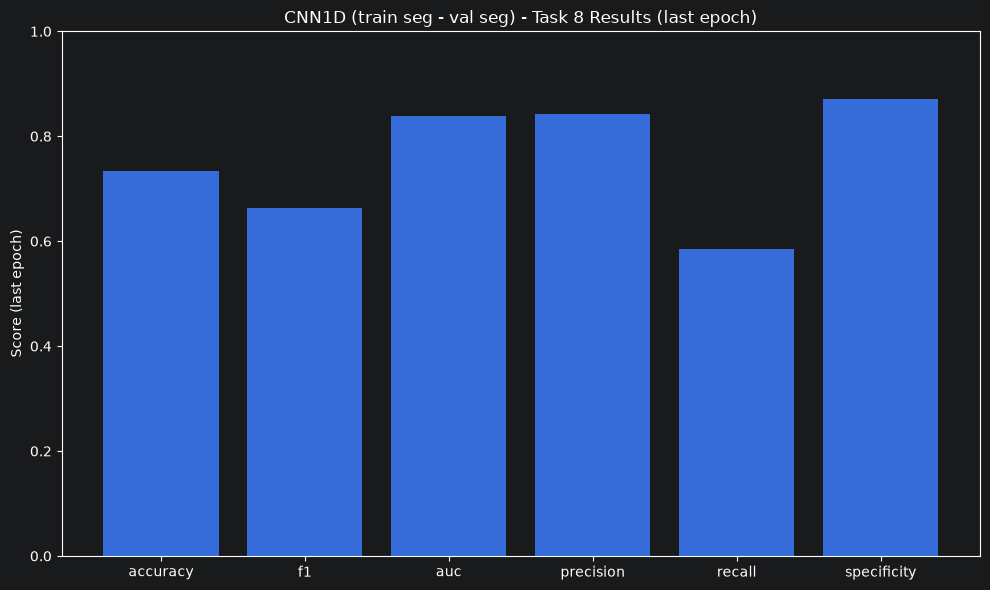

In [2]:
# =====================================
# RUN EXPERIMENT
# task 8 -> y_speed_velocity_pressure_derivative
# =====================================

runner = RunFullySegmentCNN(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[8],
    feature_names=("y",),
    engineered_features=("speed", "velocity", "pressure_derivative",),
    window_size=256,
    batch_size=16,
    epochs=50,
    learning_rate=1e-3,
    regularization=1e-3,
    n_splits=5,
    normalize=True,
    seed=42,
    device=("cuda" if torch.cuda.is_available() else "cpu"),
    aggregation="mean",
    output_dir=_project_path("experiments/ant/cnn1D/raw_segment(train_seg - val_seg)/Task_8/y_speed_velocity_pressure_derivative"),
    training_cfg={
        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
        "monitor_metric": "auc",
        "early_stopping_patience": float("inf"),
        "min_delta": 0.0,
        "results_writer": "csv",
        "save_metrics": True,
    },
)

summary = runner.run()

# =====================================
# RESULTS (last epoch)
# =====================================

averages = summary["averages"]

print("\n=== FINAL RESULTS (last epoch) ===")

print(f"Accuracy:    {averages['last_val_accuracy']:.4f}")
print(f"F1 Score:    {averages['last_val_f1']:.4f}")
print(f"AUC:         {averages['last_val_auc']:.4f}")
print(f"Precision:   {averages['last_val_precision']:.4f}")
print(f"Recall:      {averages['last_val_recall']:.4f}")
print(f"Specificity: {averages['last_val_specificity']:.4f}")

# =====================================
# BUILD DATAFRAME
# =====================================

df = pd.DataFrame([{
    "accuracy": averages["last_val_accuracy"],
    "f1": averages["last_val_f1"],
    "auc": averages["last_val_auc"],
    "precision": averages["last_val_precision"],
    "recall": averages["last_val_recall"],
    "specificity": averages["last_val_specificity"],
}])

# =====================================
# PLOT
# =====================================

metrics = [
    "accuracy",
    "f1",
    "auc",
    "precision",
    "recall",
    "specificity",
]

values = [
    averages[f"last_val_{m}"]
    for m in metrics
]

plt.figure(figsize=(10, 6))

plt.bar(
    metrics,
    values,
)

plt.ylim(0, 1)

plt.ylabel("Score (last epoch)")

plt.title(
    "CNN1D (train seg - val seg) - Task 8 Results (last epoch)"
)

plt.tight_layout()

plt.show()

[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6833 | train_accuracy=0.5693 | train_f1=0.6025 | train_auc=0.5944 | train_precision=0.5805 | train_recall=0.6263 | train_specificity=0.5072 | val_loss=0.6125 | val_accuracy=0.7333 | val_f1=0.7143 | val_auc=0.7857 | val_precision=0.8333 | val_recall=0.6250 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.6535 | train_accuracy=0.6022 | train_f1=0.6329 | train_auc=0.6558 | train_precision=0.6098 | train_recall=0.6579 | train_specificity=0.5415 | val_loss=0.6035 | val_accuracy=0.6667 | val_f1=0.6154 | val_auc=0.8036 | val_precision=0.8000 | val_recall=0.5000 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.6522 | train_accuracy=0.6173 | train_f1=0.6482 | train_auc=0.6581 | train_precision=0.6223 | train_recall=0.6763 | train_specificity=0.5530 | val_loss=0.5599 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=

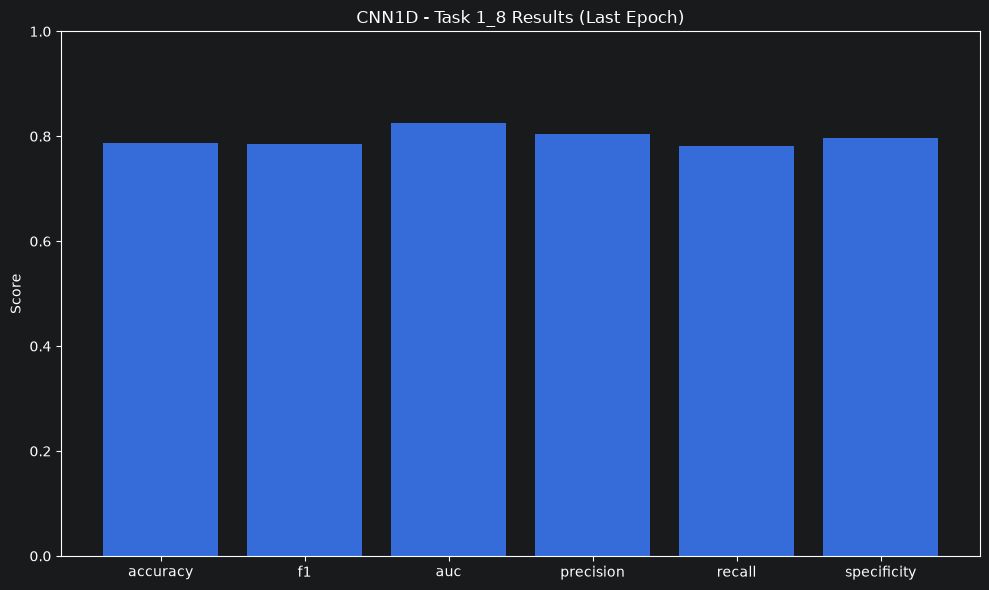


[Grad-CAM] patient=00003, label=1, shape=(512, 3), valid=512/512
Conv1d trovati: ['features.0', 'features.4', 'features.8']
target_layer = features.8

                                      Executing SignalGrad-CAM                                      

AVAILABLE EXPLAINERS:
 - Explainer identifier 'Grad-CAM': Gradient-weighted Class Activation Mapping
 - Explainer identifier 'HiResCAM': High-Resolution Class Activation Mapping

SEARCHING FOR NETWORK LAYERS:
Please verify that your network contains at least one 1D or 2D convolutional layer, and take note of
the names of the layers that are of interest to you. If the desired layer is not present in the list
below, it can still be accessed using the name by which it is defined in the network. Also, check
whether the model ends with an activation function from the Softmax family (such as Sigmoid or
Softmax). Even if this activation function is not listed below, you must indicate its presence using
the appropriate argument in the 'get_cam'

C:\Users\Utente\parkinson_disease\.venv\Lib\site-packages\signal_grad_cam\cam_builder.py:1277: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  np.divide(cams - minima, maxima - minima, where=(maxima - minima) != 0))


<Figure size 640x480 with 0 Axes>

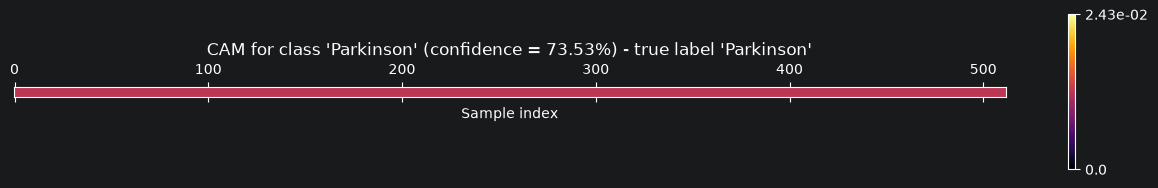

lib cam (uint8): shape (512, 1) min 76 max 76
lib range raw (min, max): [0.]
mask.sum(): 512 / 512
runner.device: cpu | builder.device: cpu
Chiavi disponibili: ['Grad-CAM_features.8_class1']
Probabilit﷿﷿ classe spiegata: [0.73534876]


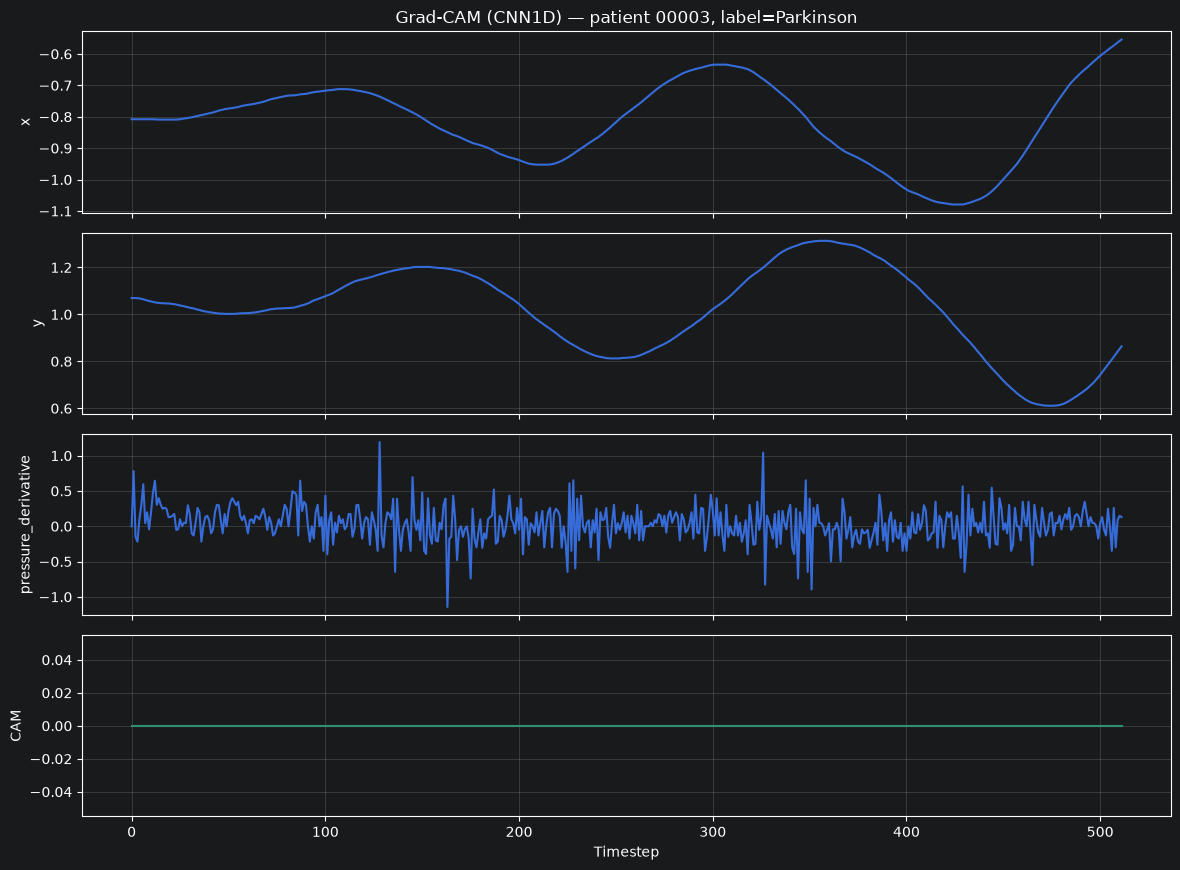

In [7]:
# =====================================
# Dipendenze
# =====================================
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from signal_grad_cam import TorchCamBuilder
from signal_grad_cam.cam_builder import CamBuilder

# =====================================
# 0. Patch del bug della colorbar (float() su array di 1 elemento)
# =====================================
def _safe_set_colorbar(bar_ranges=None, batch_idx=None, norm=None, ax=None):
    if bar_ranges is None:
        return
    lo = float(np.asarray(bar_ranges[0][batch_idx]).reshape(-1)[0])
    hi = float(np.asarray(bar_ranges[1][batch_idx]).reshape(-1)[0])
    if norm is None:
        cbar = plt.colorbar()
    else:
        from mpl_toolkits.axes_grid1 import make_axes_locatable
        sm = plt.cm.ScalarMappable(cmap="inferno", norm=norm)
        sm.set_array([])
        cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.05)
        cbar = plt.colorbar(sm, cax=cax)
    fmt = lambda v: str(v) if v == 0 else "{:.2e}".format(v)
    cbar.ax.get_yaxis().set_ticks([cbar.vmin, cbar.vmax], labels=[fmt(lo), fmt(hi)])

CamBuilder._CamBuilder__set_colorbar = staticmethod(_safe_set_colorbar)

# =====================================
# 1. Esegui l'esperimento
# =====================================
runner = RunFullySegmentCNN(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[1, 8],
    feature_names=("x", "y"),
    engineered_features=("pressure_derivative",),
    window_size=512,
    batch_size=16,
    epochs=250,
    learning_rate=1e-3,
    regularization=1e-6,
    n_splits=5,
    normalize=True,
    seed=42,
    device=("cuda" if torch.cuda.is_available() else "cpu"),
    aggregation="mean",
    output_dir=_project_path(
        "experiments/cnn1D/raw_segment + cnn(train_seg - val_seg)/Task_1_8/xy_pressure_derivative"
    ),
    training_cfg={
        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
        "monitor_metric": "auc",
        "early_stopping_patience": float("inf"),
        "min_delta": 0.0,
        "results_writer": "csv",
        "save_metrics": True,
    },
)

summary = runner.run()

# =====================================
# 2. Risultati (ultima epoca)
# =====================================
averages = summary["averages"]

print("\n=== FINAL RESULTS (Last Epoch) ===")
print(f"Accuracy:    {averages['last_val_accuracy']:.4f}")
print(f"F1 Score:    {averages['last_val_f1']:.4f}")
print(f"AUC:         {averages['last_val_auc']:.4f}")
print(f"Precision:   {averages['last_val_precision']:.4f}")
print(f"Recall:      {averages['last_val_recall']:.4f}")
print(f"Specificity: {averages['last_val_specificity']:.4f}")

metrics = ["accuracy", "f1", "auc", "precision", "recall", "specificity"]
values = [averages[f"last_val_{m}"] for m in metrics]

plt.figure(figsize=(10, 6))
plt.bar(metrics, values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("CNN1D - Task 1_8 Results (Last Epoch)")
plt.tight_layout()
plt.show()

# =====================================
# 3. Grad-CAM
# =====================================
FOLD = 1

if not hasattr(runner, "trained_models_") or FOLD not in runner.trained_models_:
    raise AttributeError(
        "Il runner non ha salvato i modelli. "
        "Assicurati di aver modificato la classe RunFullySegmentCNN "
        "e di aver riavviato il kernel."
    )

model = runner.trained_models_[FOLD]
model.eval()
model.to(runner.device)

val_ds = runner.val_datasets_[FOLD]       # gi﷿﷿ normalizzato (_NormalizedDataset)

sample = val_ds[0]
segment = sample["segment"].float()       # [T, F]
mask = sample["mask"].bool()              # [T]
label = int(sample["label"])
patient_id = sample["patient_id"]

print(
    f"\n[Grad-CAM] patient={patient_id}, label={label}, "
    f"shape={tuple(segment.shape)}, valid={int(mask.sum())}/{mask.numel()}"
)

# L'item resta [T, F]: la libreria aggiunge da sola la dimensione batch
def preprocess_fn(seg):
    return torch.from_numpy(seg).float()

conv_names = [n for n, m in model.named_modules() if isinstance(m, nn.Conv1d)]
print("Conv1d trovati:", conv_names)
target_layer = conv_names[-1]
print("target_layer =", target_layer)

class_names = ["Healthy", "Parkinson"]

cam_builder = TorchCamBuilder(
    model=model,
    transform_fn=preprocess_fn,
    class_names=class_names,
    time_axs=0,          # nell'item [T, F] il tempo ﷿﷿ l'asse 0
)

import cv2
print("cv2 version:", cv2.__version__)

_orig_resize = cv2.resize
def _resize_1d_safe(src, dsize, *args, **kwargs):
    # un array 1D va letto come colonna (T,1), non come riga (1,T)
    if isinstance(src, np.ndarray) and src.ndim == 1:
        src = src.reshape(-1, 1)
    return _orig_resize(src, dsize, *args, **kwargs)
cv2.resize = _resize_1d_safe

cam_dict, probs_dict, ranges_dict = cam_builder.get_cam(
    data_list=[segment.numpy()],
    data_labels=[label],
    target_classes=[label],
    explainer_types="Grad-CAM",
    target_layers=target_layer,
    softmax_final=False,                                        # VanillaCNN1D restituisce logits
    extra_inputs_list=[mask.unsqueeze(0).to(runner.device)],    # maschera di padding -> forward(x, mask)
)

raw = np.asarray(cam_dict[item_key][0])
print("lib cam (uint8): shape", raw.shape, "min", raw.min(), "max", raw.max())
print("lib range raw (min, max):", np.ravel(ranges_dict[item_key][0]) if isinstance(ranges_dict, dict) else ranges_dict)
print("mask.sum():", int(mask.sum()), "/", mask.numel())
print("runner.device:", runner.device, "| builder.device:", cam_builder.device)

# Chiave usata dalla libreria: "<explainer>_<layer>_class<target>"
item_key = f"Grad-CAM_{target_layer}_class{label}"
print("Chiavi disponibili:", list(cam_dict.keys()))
print("Probabilit﷿﷿ classe spiegata:", probs_dict[item_key])

cam_array = np.asarray(cam_dict[item_key][0], dtype=np.float32).squeeze()   # [T]

T = segment.shape[0]
if cam_array.shape[0] != T:
    idx_old = np.linspace(0, 1, cam_array.shape[0])
    idx_new = np.linspace(0, 1, T)
    cam_array = np.interp(idx_new, idx_old, cam_array)

cam_array[int(mask.sum()):] = 0           # il padding non deve contribuire
cam_array = cam_array - cam_array.min()
if cam_array.max() > 0:
    cam_array = cam_array / cam_array.max()

# =====================================
# 4. Plot: segnale + CAM
# =====================================
feature_names_plot = list(runner.feature_names) + list(runner.engineered_features)
n_features = segment.shape[1]
t_axis = np.arange(T)

fig, axes = plt.subplots(n_features + 1, 1, figsize=(12, 2.2 * (n_features + 1)), sharex=True)

for i in range(n_features):
    ax = axes[i]
    ax.plot(t_axis, segment[:, i].numpy(), color="C0")
    ax.set_ylabel(feature_names_plot[i])
    ax.grid(True, alpha=0.3)
    if mask.sum() < T:
        ax.axvspan(int(mask.sum()), T, color="gray", alpha=0.15)

axes[0].set_title(f"Grad-CAM (CNN1D) ﷿﷿﷿ patient {patient_id}, label={class_names[label]}")

ax_cam = axes[-1]
ax_cam.plot(t_axis, cam_array, color="C3", linewidth=1.5)
ax_cam.fill_between(t_axis, 0, cam_array, color="C3", alpha=0.35)
ax_cam.set_ylabel("CAM")
ax_cam.set_xlabel("Timestep")
ax_cam.grid(True, alpha=0.3)
if mask.sum() < T:
    ax_cam.axvspan(int(mask.sum()), T, color="gray", alpha=0.15)

plt.tight_layout()
plt.show()

cv2 version: 5.0.0
Conv1d trovati: ['features.0', 'features.4', 'features.8']
target_layer = features.8

                                      Executing SignalGrad-CAM                                      

AVAILABLE EXPLAINERS:
 - Explainer identifier 'Grad-CAM': Gradient-weighted Class Activation Mapping
 - Explainer identifier 'HiResCAM': High-Resolution Class Activation Mapping

SEARCHING FOR NETWORK LAYERS:
Please verify that your network contains at least one 1D or 2D convolutional layer, and take note of
the names of the layers that are of interest to you. If the desired layer is not present in the list
below, it can still be accessed using the name by which it is defined in the network. Also, check
whether the model ends with an activation function from the Softmax family (such as Sigmoid or
Softmax). Even if this activation function is not listed below, you must indicate its presence using
the appropriate argument in the 'get_cam' function. Note that in binary classification n

<Figure size 640x480 with 0 Axes>

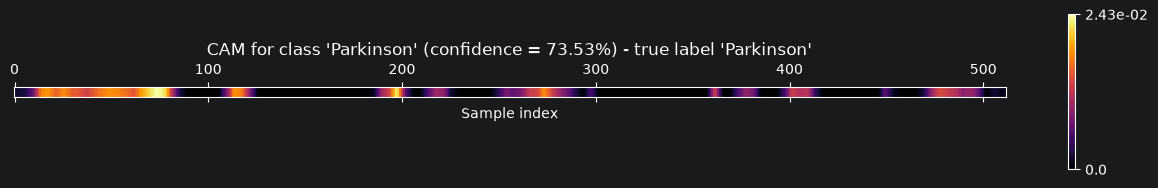

<Figure size 640x480 with 0 Axes>

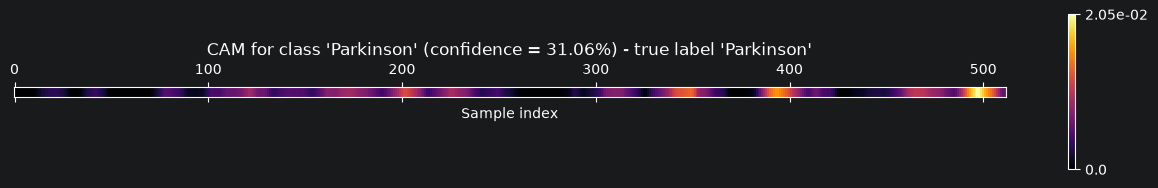

<Figure size 640x480 with 0 Axes>

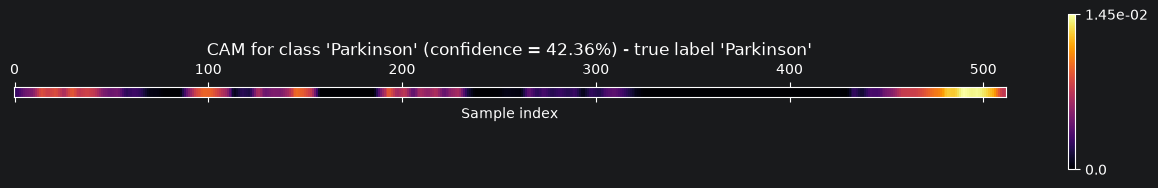

<Figure size 640x480 with 0 Axes>

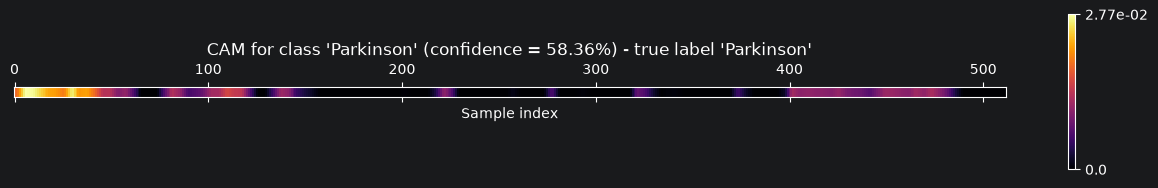

<Figure size 640x480 with 0 Axes>

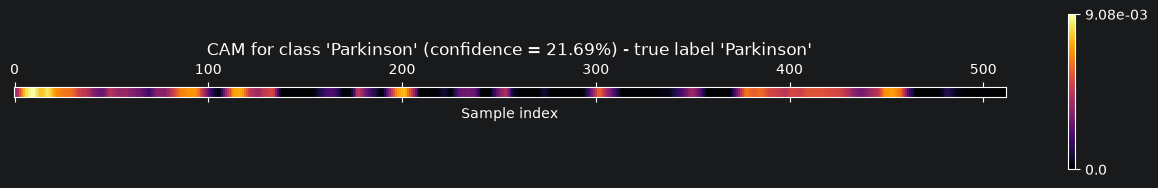


[Registrazione] patient=00003 task=1 label=Parkinson finestre=5 timestep=2071
 idx  start  end  valid  explained_class     prob  raw_max
   0      0  512    512                1 0.735349 0.024317
   1    512 1024    512                1 0.310610 0.020544
   2   1024 1536    512                1 0.423566 0.014506
   3   1536 2048    512                1 0.583566 0.027650
   4   1559 2071    512                1 0.216937 0.009076
CAM: min 0.0 max 1.0


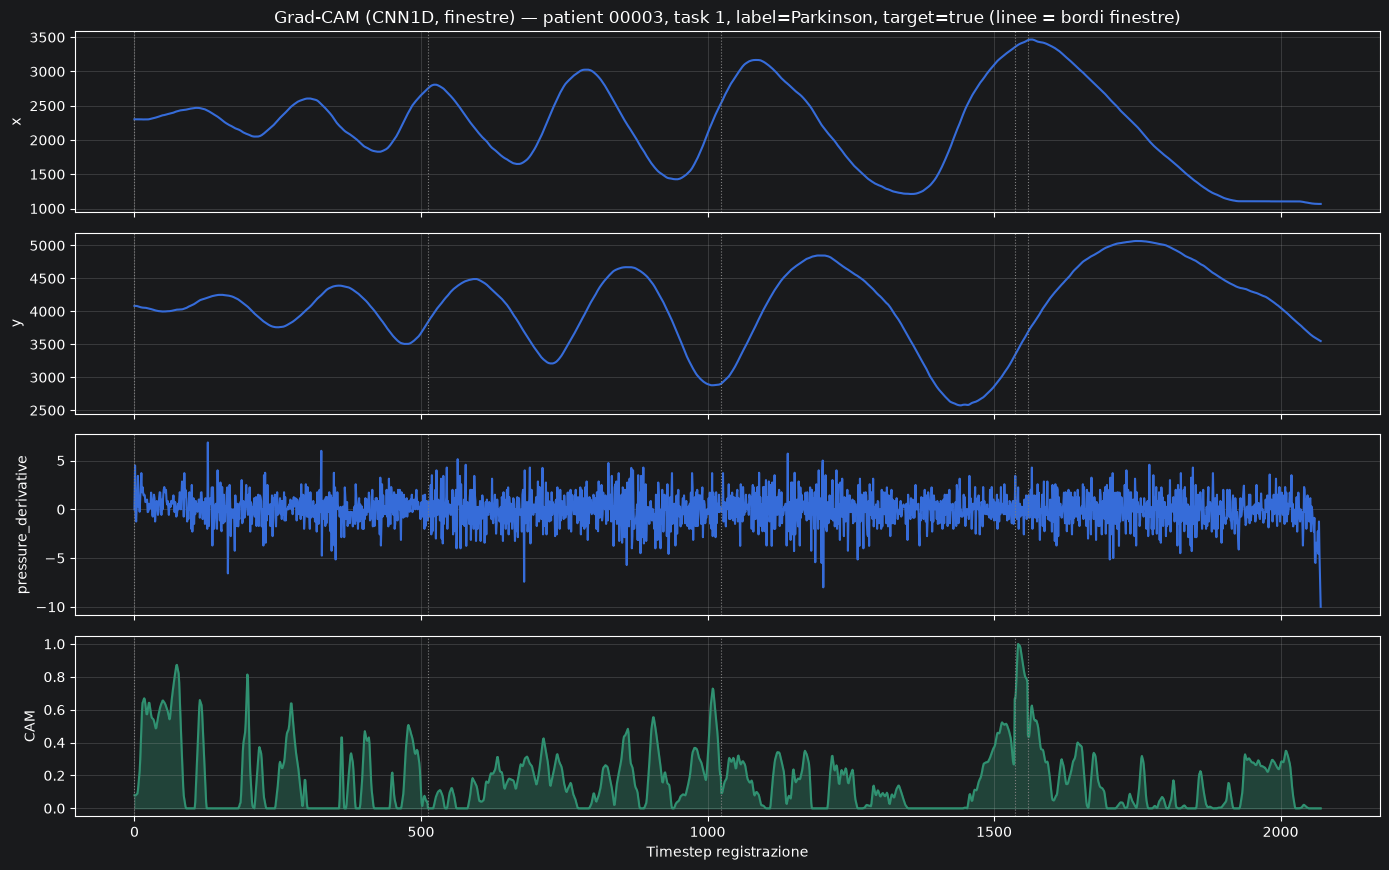

<Figure size 640x480 with 0 Axes>

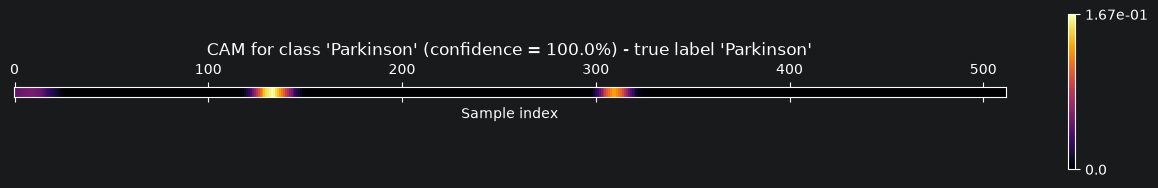

<Figure size 640x480 with 0 Axes>

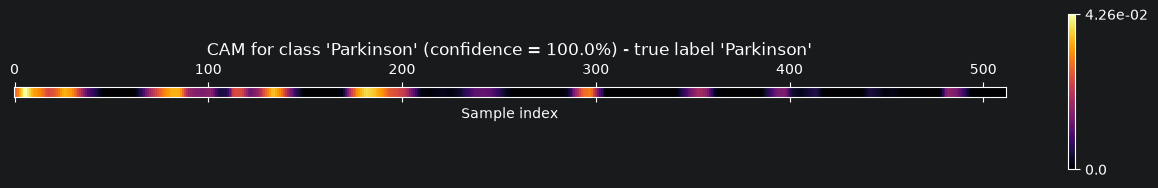

<Figure size 640x480 with 0 Axes>

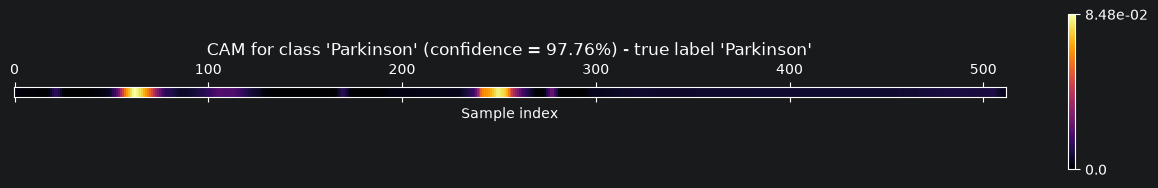

<Figure size 640x480 with 0 Axes>

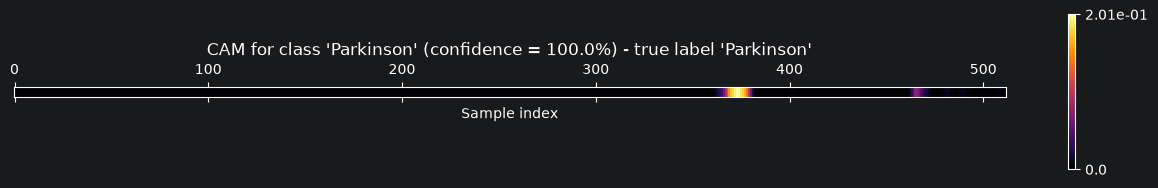

<Figure size 640x480 with 0 Axes>

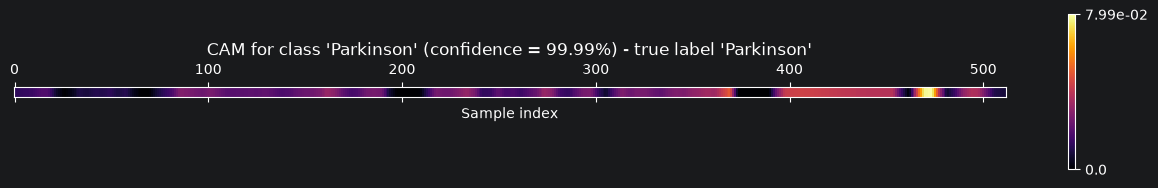

<Figure size 640x480 with 0 Axes>

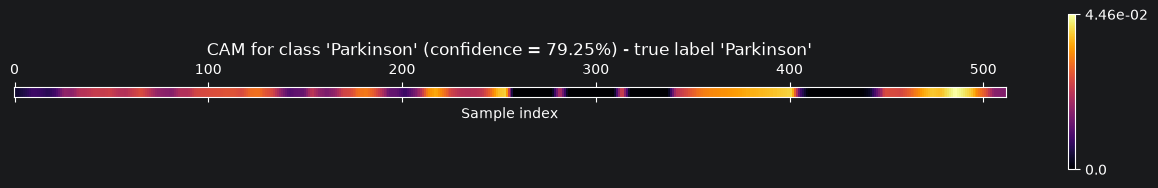

<Figure size 640x480 with 0 Axes>

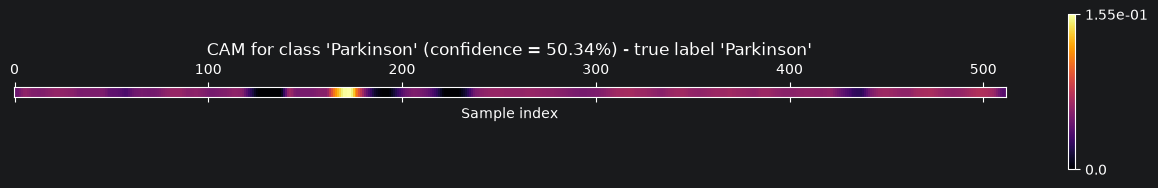

<Figure size 640x480 with 0 Axes>

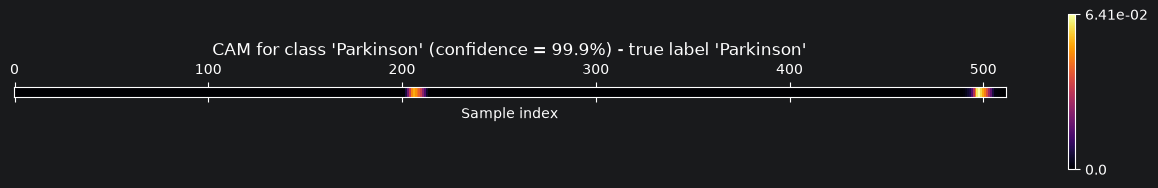

<Figure size 640x480 with 0 Axes>

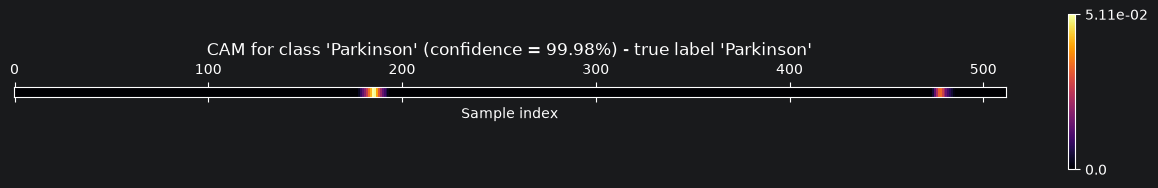


[Registrazione] patient=00003 task=8 label=Parkinson finestre=9 timestep=4118
 idx  start  end  valid  explained_class     prob  raw_max
   5      0  512    512                1 1.000000 0.166662
   6    512 1024    512                1 1.000000 0.042570
   7   1024 1536    512                1 0.977580 0.084810
   8   1536 2048    512                1 1.000000 0.201226
   9   2048 2560    512                1 0.999875 0.079881
  10   2560 3072    512                1 0.792547 0.044568
  11   3072 3584    512                1 0.503406 0.154664
  12   3584 4096    512                1 0.998999 0.064132
  13   3606 4118    512                1 0.999846 0.051103
CAM: min 0.0 max 1.0


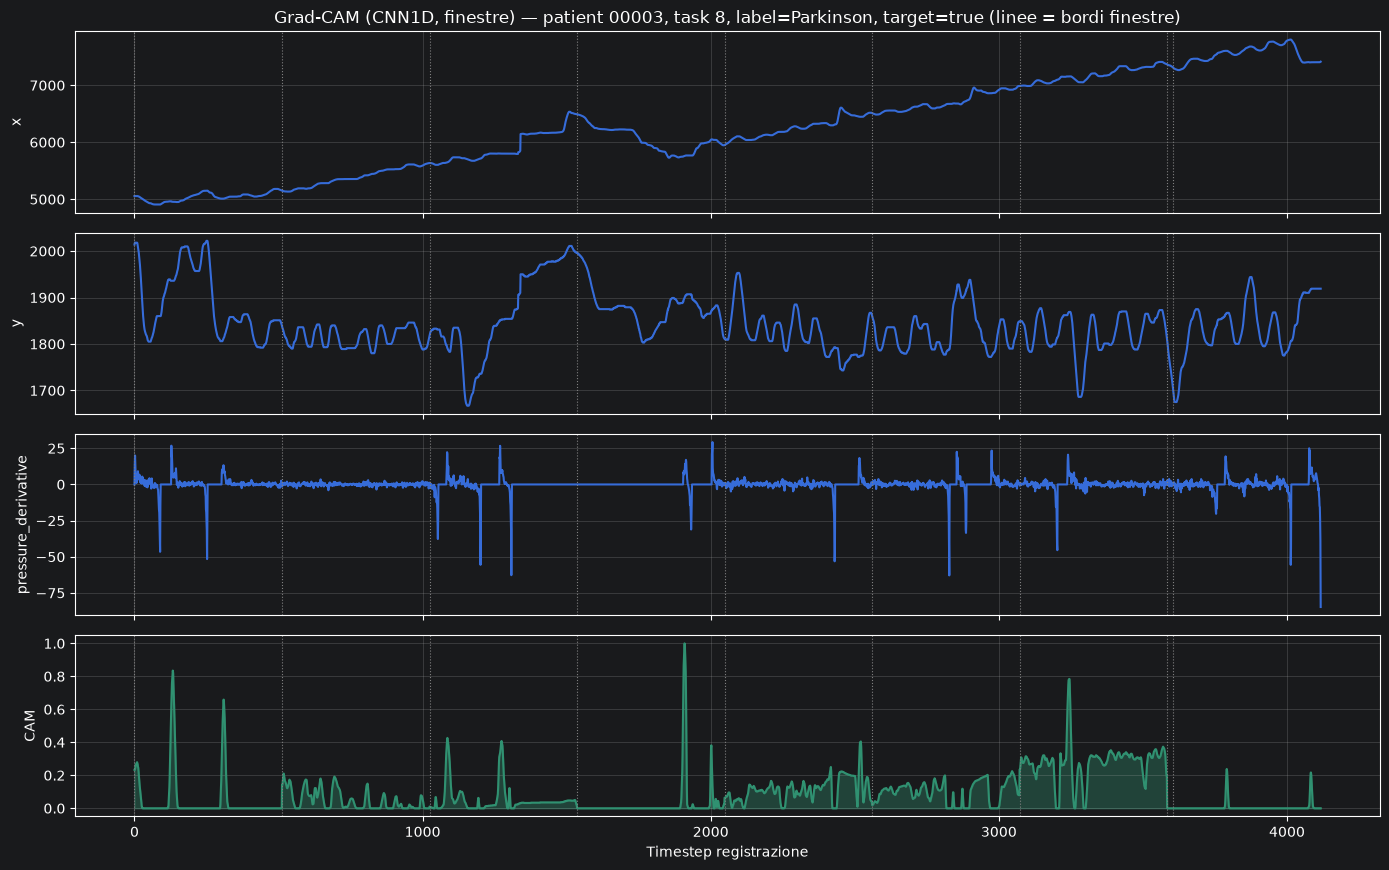


[Decisione] Paziente 00003 | finestre N=14 (task [1, 8])
label vera     : Parkinson
logit medi     : [-3.3223  3.4612]  ->  decisione: Parkinson  (corretta)
classe spiegata: Parkinson


<Figure size 640x480 with 0 Axes>

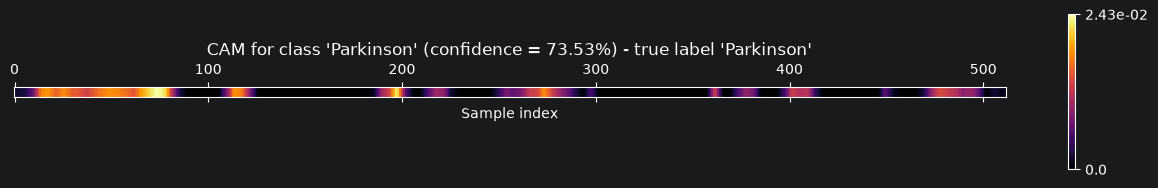

<Figure size 640x480 with 0 Axes>

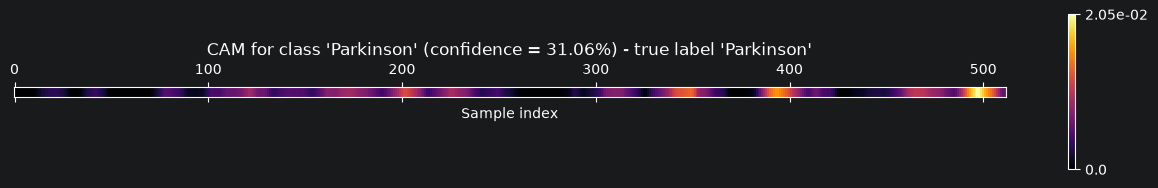

<Figure size 640x480 with 0 Axes>

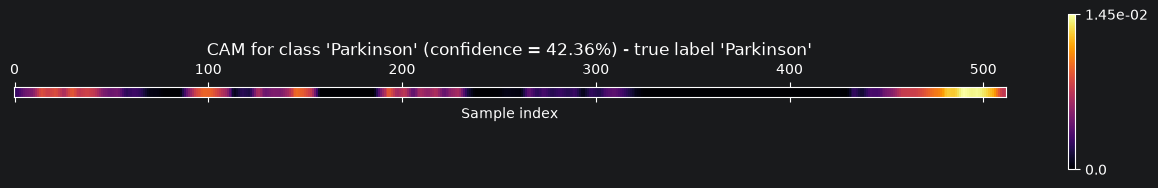

<Figure size 640x480 with 0 Axes>

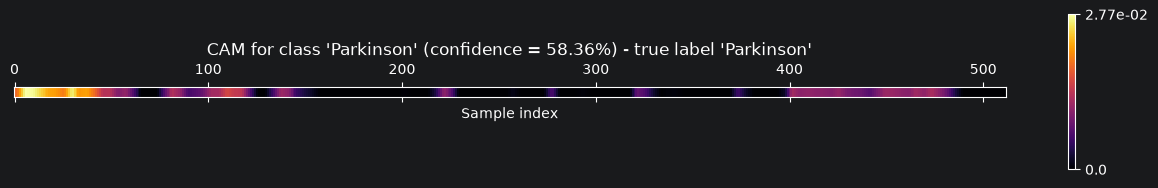

<Figure size 640x480 with 0 Axes>

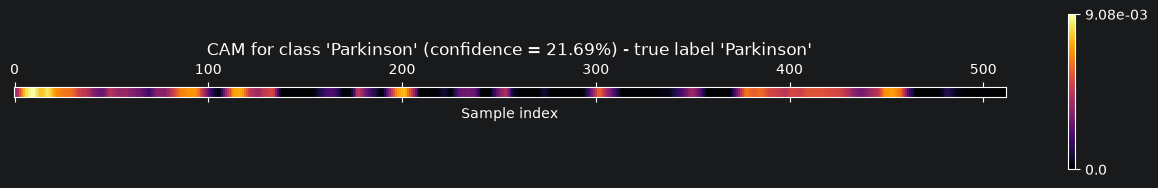

<Figure size 640x480 with 0 Axes>

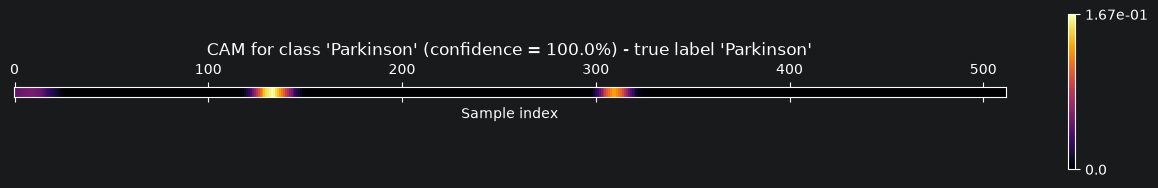

<Figure size 640x480 with 0 Axes>

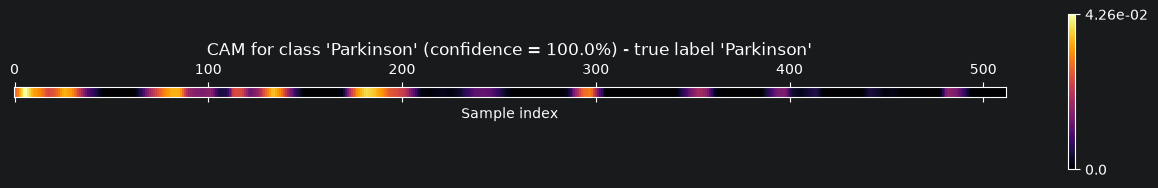

<Figure size 640x480 with 0 Axes>

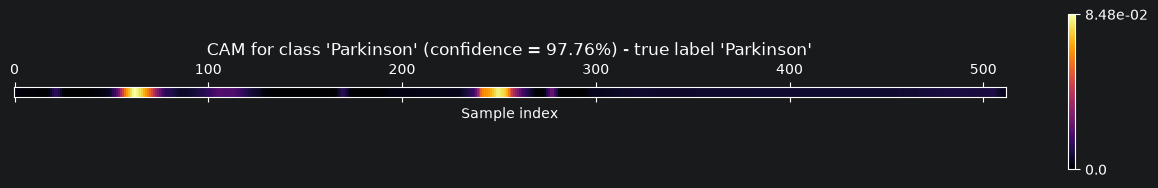

<Figure size 640x480 with 0 Axes>

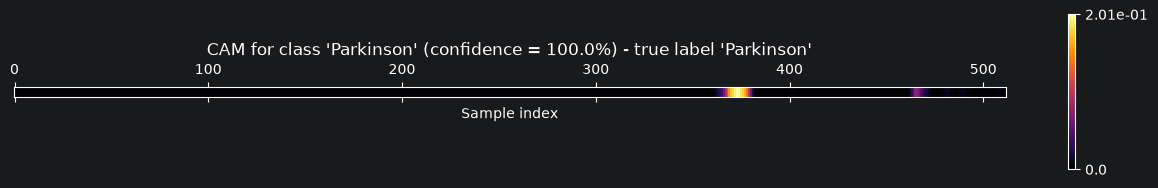

<Figure size 640x480 with 0 Axes>

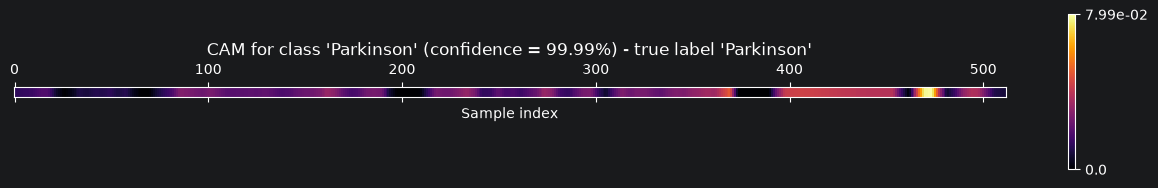

<Figure size 640x480 with 0 Axes>

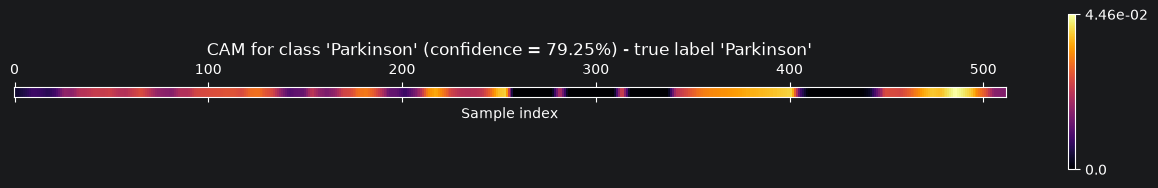

<Figure size 640x480 with 0 Axes>

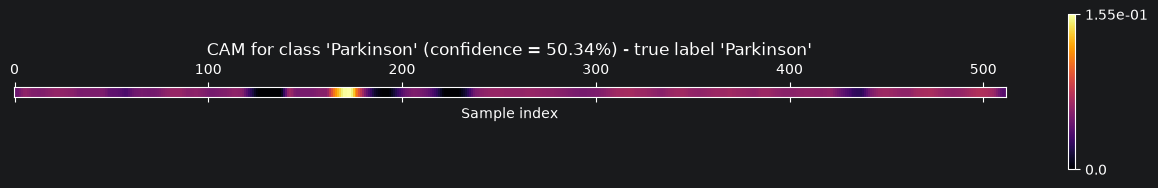

<Figure size 640x480 with 0 Axes>

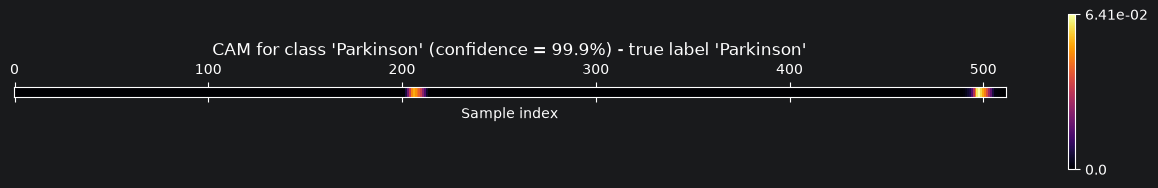

<Figure size 640x480 with 0 Axes>

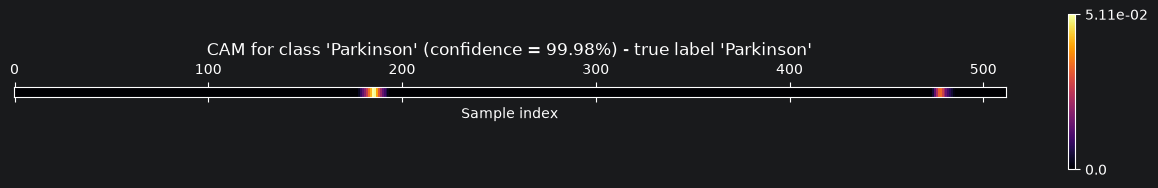

 task  start  end  valid  logit_0  logit_1  contrib_margin
    1      0  512    512  -0.5863   0.4356          0.0730
    1    512 1024    512   0.2474  -0.5498         -0.0569
    1   1024 1536    512   0.2011  -0.1070         -0.0220
    1   1536 2048    512  -0.2934   0.0440          0.0241
    1   1559 2071    512   0.5489  -0.7347         -0.0917
    8      0  512    512  -9.9480  10.2107          1.4399
    8    512 1024    512 -12.3324  13.4206          1.8395
    8   1024 1536    512  -1.8483   1.9268          0.2697
    8   1536 2048    512  -9.5330  10.7546          1.4491
    8   2048 2560    512  -4.2702   4.7152          0.6418
    8   2560 3072    512  -0.6828   0.6575          0.0957
    8   3072 3584    512  -0.2174  -0.2038          0.0010
    8   3584 4096    512  -3.4402   3.4654          0.4933
    8   3606 4118    512  -4.3576   4.4218          0.6271
Somma contributi al margine: 6.7835 (>0 => decisione per Parkinson)


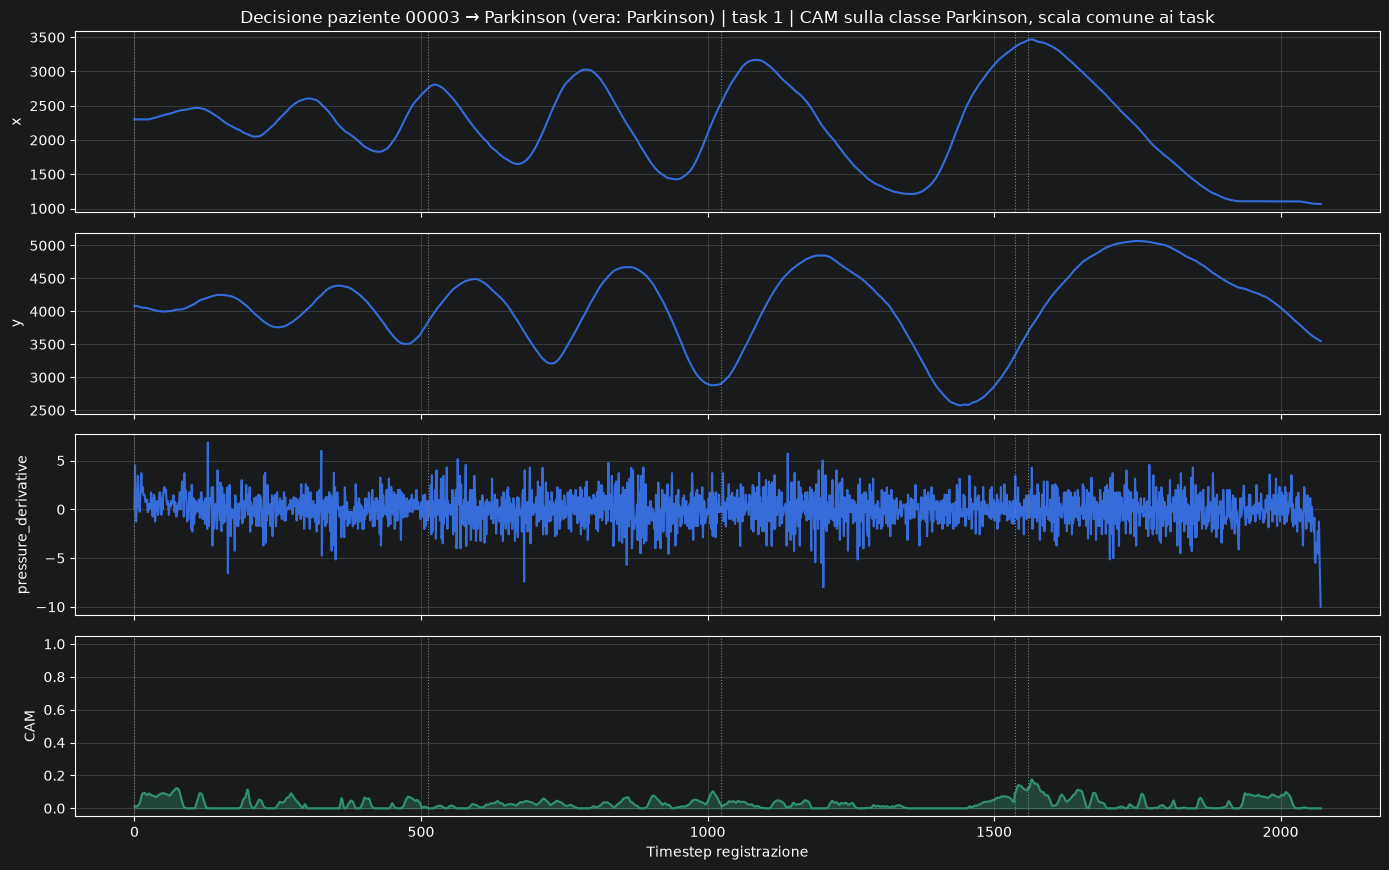

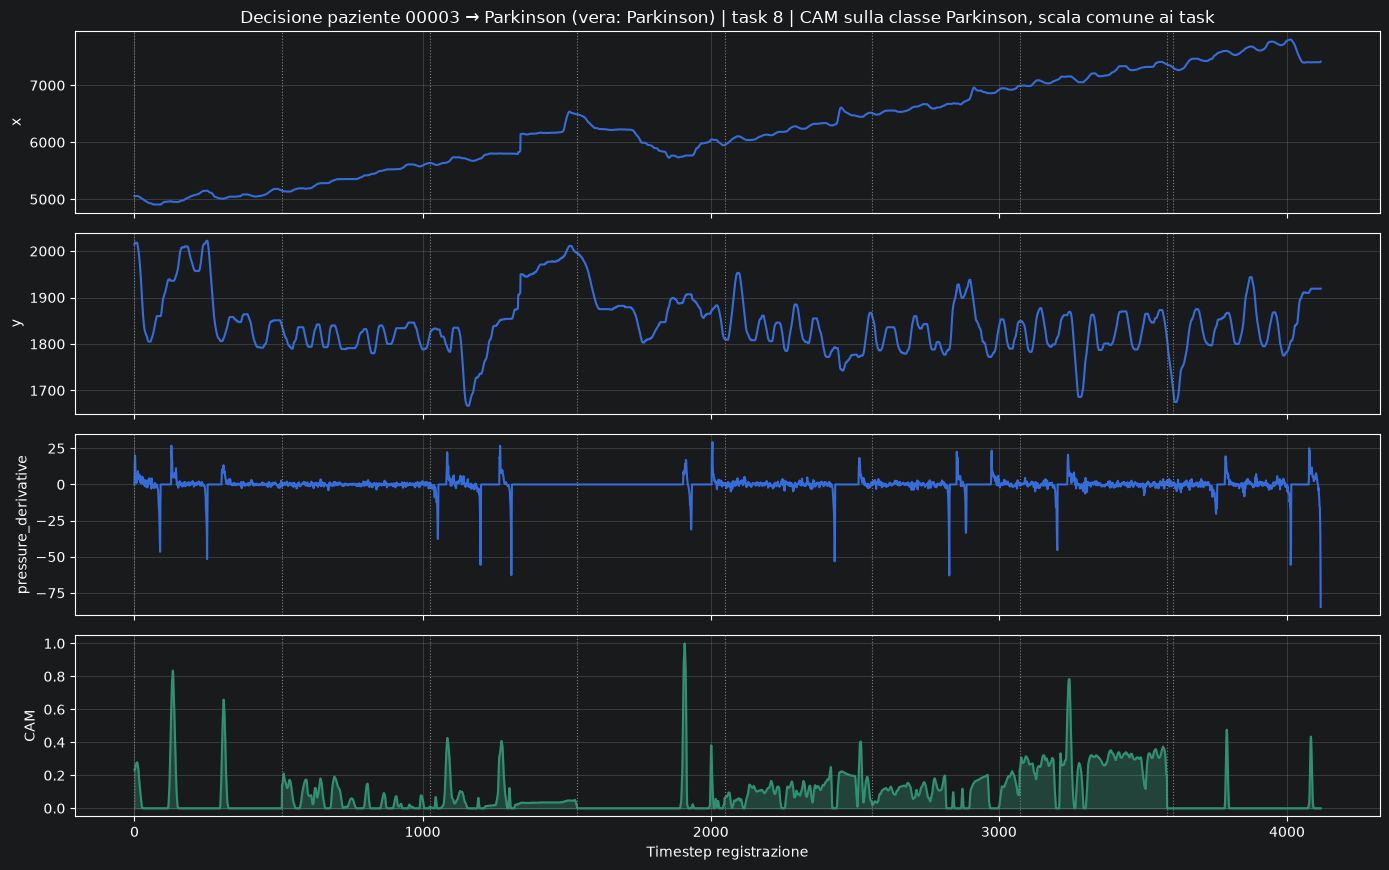

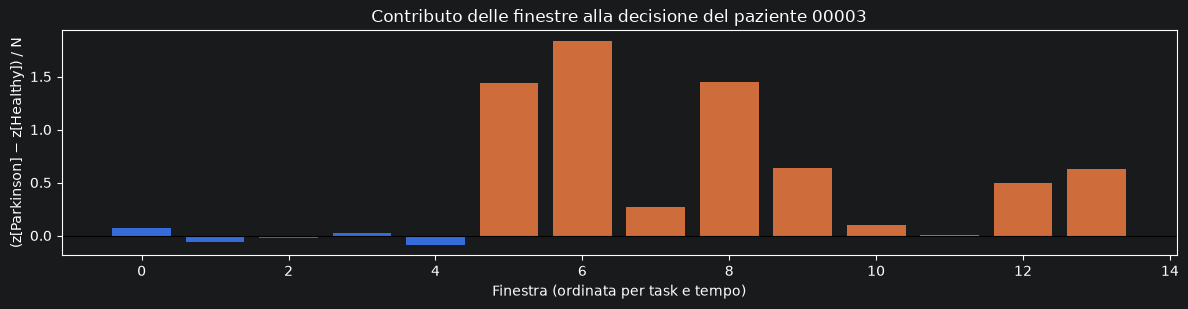

In [10]:
# =====================================
# CELLA GRAD-CAM COMPLETA ﷿﷿﷿ RunFullySegmentCNN (finestre fisse, niente HMM)
# Senza riallenare: richiede `runner` gi﷿﷿ in memoria
#  - explain_recording: CAM su una registrazione (paziente x task)
#  - explain_decision : CAM sulla decisione del paziente (media dei logit delle finestre)
# =====================================
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import cv2
from signal_grad_cam import TorchCamBuilder
from signal_grad_cam.cam_builder import CamBuilder
import signal_grad_cam.cam_builder as _cb

warnings.filterwarnings("ignore", message=".*'where' used without 'out'.*")

# --- patch (a): colorbar ---
def _safe_set_colorbar(bar_ranges=None, batch_idx=None, norm=None, ax=None):
    if bar_ranges is None:
        return
    lo = float(np.asarray(bar_ranges[0][batch_idx]).reshape(-1)[0])
    hi = float(np.asarray(bar_ranges[1][batch_idx]).reshape(-1)[0])
    if norm is None:
        cbar = plt.colorbar()
    else:
        from mpl_toolkits.axes_grid1 import make_axes_locatable
        sm = plt.cm.ScalarMappable(cmap="inferno", norm=norm)
        sm.set_array([])
        cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.05)
        cbar = plt.colorbar(sm, cax=cax)
    fmt = lambda v: str(v) if v == 0 else "{:.2e}".format(v)
    cbar.ax.get_yaxis().set_ticks([cbar.vmin, cbar.vmax], labels=[fmt(lo), fmt(hi)])

CamBuilder._CamBuilder__set_colorbar = staticmethod(_safe_set_colorbar)

# --- patch (b): cv2.resize su array 1D (OpenCV 5.x), solo dentro signal_grad_cam ---
print("cv2 version:", cv2.__version__)

class _Cv2Shim:
    def __init__(self, real):
        self._real = real
    def __getattr__(self, name):
        return getattr(self._real, name)
    def resize(self, src, dsize, *args, **kwargs):
        src = np.asarray(src)
        if src.ndim == 1:                              # CAM 1D: dsize = (1, T)
            w, h = dsize
            n = src.shape[0]
            x = (np.arange(h) + 0.5) * n / h - 0.5     # stessa convenzione bilineare di cv2
            out = np.interp(x, np.arange(n), src.astype(np.float32))
            if src.dtype == np.uint8:
                out = np.clip(np.rint(out), 0, 255)
            out = out.astype(src.dtype).reshape(-1, 1)
            return np.repeat(out, w, axis=1)           # shape (T, 1)
        return self._real.resize(src, dsize, *args, **kwargs)

_cb.cv2 = _Cv2Shim(getattr(_cb.cv2, "_real", _cb.cv2))

# --- controllo: il runner deve avere i modelli (i fold partono da 1) ---
FOLD = 1
if "runner" not in globals():
    raise NameError("`runner` non esiste: il kernel ﷿﷿ stato riavviato. Esegui prima l'addestramento.")
if not hasattr(runner, "trained_models_") or FOLD not in runner.trained_models_:
    raise AttributeError("Il runner non ha i modelli addestrati: riesegui l'addestramento.")

model = runner.trained_models_[FOLD]
model.eval()
model.to(runner.device)

val_ds = runner.val_datasets_[FOLD]                       # GI﷿﷿ normalizzato (_NormalizedDataset)
norm_payload = runner.normalization_payloads_[FOLD]
mean = torch.tensor(norm_payload["mean"], dtype=torch.float32)
std = torch.tensor(norm_payload["std"], dtype=torch.float32).clamp_min(runner.normalization_eps)

class_names = ["Healthy", "Parkinson"]
feature_names_plot = list(runner.feature_names) + list(runner.engineered_features)

conv_names = [n for n, m in model.named_modules() if isinstance(m, nn.Conv1d)]
print("Conv1d trovati:", conv_names)
TARGET_LAYER = conv_names[-1]
print("target_layer =", TARGET_LAYER)

def preprocess_fn(seg):
    return torch.from_numpy(seg).float()          # la libreria aggiunge il batch

cam_builder = TorchCamBuilder(
    model=model,
    transform_fn=preprocess_fn,
    class_names=class_names,
    time_axs=0,                                   # item [T, F]: il tempo ﷿﷿ l'asse 0
)

# Campioni del fold di validazione (una sola lettura del dataset)
samples = [val_ds[i] for i in range(len(val_ds))]
available = sorted({(str(s["patient_id"]), int(s["task_id"])) for s in samples})
print("Registrazioni disponibili nel fold di validazione:", available)


# =====================================
# Funzioni comuni
# =====================================
def _clear_cam_hooks():
    # la libreria non rimuove i suoi hook: li svuoto prima di ogni forward/get_cam
    dict(model.named_modules())[TARGET_LAYER]._forward_hooks.clear()


def _prepare(s):
    """Finestra -> (mask, valid, seg_raw per il plot, seg gi﷿﷿ normalizzato)."""
    mask = s["mask"].bool()
    seg = s["segment"].float()                    # gi﷿﷿ normalizzato, padding a zero
    valid = int(mask.sum())
    seg_raw = seg * std + mean                    # ricostruzione del segnale originale (solo per il plot)
    return mask, valid, seg_raw, seg


def _segment_logits(seg, mask):
    _clear_cam_hooks()
    with torch.no_grad():
        z = model(seg.unsqueeze(0).to(runner.device), mask=mask.unsqueeze(0).to(runner.device))
        if isinstance(z, tuple):
            z = z[0]
    return z[0].cpu().numpy()


def _segment_cam(seg, mask, cls, label):
    """Grad-CAM (libreria) su una finestra. Ritorna cam in [0,1], massimo grezzo, prob della classe."""
    _clear_cam_hooks()
    cam_dict, probs_dict, ranges_dict = cam_builder.get_cam(
        data_list=[seg.numpy()],
        data_labels=[label],
        target_classes=[cls],
        explainer_types="Grad-CAM",
        target_layers=TARGET_LAYER,
        softmax_final=False,
        extra_inputs_list=[mask.unsqueeze(0).to(runner.device)],
    )
    key = f"Grad-CAM_{TARGET_LAYER}_class{cls}"
    cam01 = np.asarray(cam_dict[key][0], dtype=np.float32).squeeze() / 255.0
    raw_max = float(np.ravel(ranges_dict[key][1])[0])
    prob = float(np.ravel(probs_dict[key])[0])
    return cam01, raw_max, prob


def _timeline(wins):
    """
    Rimette le finestre sull'asse temporale della registrazione usando `start`.
    Dove le finestre si sovrappongono (ultima finestra con include_last) il segnale coincide,
    mentre le CAM vengono sommate e `count` dice quante finestre coprono ogni timestep.
    """
    T = max(w["start"] + w["valid"] for w in wins)
    F = wins[0]["seg_raw"].shape[1]
    signal = np.zeros((T, F), dtype=np.float32)
    cam_sum = np.zeros(T, dtype=np.float32)
    count = np.zeros(T, dtype=np.float32)
    for w in wins:
        sl = slice(w["start"], w["start"] + w["valid"])
        signal[sl] = w["seg_raw"][: w["valid"]].numpy()
        cam_sum[sl] += w["cam"]
        count[sl] += 1
    return signal, cam_sum, count


def _plot_signal_cam(signal, cam, title, win_starts=None):
    n_features = signal.shape[1]
    t = np.arange(len(cam))
    fig, axes = plt.subplots(n_features + 1, 1, figsize=(14, 2.2 * (n_features + 1)), sharex=True)
    for j in range(n_features):
        axes[j].plot(t, signal[:, j], color="C0")
        axes[j].set_ylabel(feature_names_plot[j])
        axes[j].grid(True, alpha=0.3)
    axes[0].set_title(title)
    axes[-1].plot(t, cam, color="C3", linewidth=1.5)
    axes[-1].fill_between(t, 0, cam, color="C3", alpha=0.35)
    axes[-1].set_ylabel("CAM")
    axes[-1].set_xlabel("Timestep registrazione")
    axes[-1].set_ylim(-0.05, 1.05)
    axes[-1].grid(True, alpha=0.3)
    if win_starts is not None:                              # bordi delle finestre
        for a in axes:
            for st in win_starts:
                a.axvline(st, color="gray", linestyle=":", linewidth=0.8)
    plt.tight_layout()
    plt.show()


# =====================================
# A) CAM su una registrazione (paziente x task)
# =====================================
def explain_recording(patient_id, task_id, target="true"):
    """target = "true": classe vera; "pred": classe predetta dal modello su ciascuna finestra."""
    idxs = [i for i, s in enumerate(samples)
            if str(s["patient_id"]) == str(patient_id) and int(s["task_id"]) == int(task_id)]
    if not idxs:
        raise RuntimeError(
            f"Nessuna finestra per paziente {patient_id}, task {task_id} nel fold {FOLD}. "
            f"Disponibili: {available}"
        )
    idxs.sort(key=lambda i: int(samples[i]["start"]))
    label = int(samples[idxs[0]]["label"])

    wins, info = [], []
    for i in idxs:
        s = samples[i]
        mask, valid, seg_raw, seg = _prepare(s)
        cls = int(_segment_logits(seg, mask).argmax()) if target == "pred" else label
        cam01, raw_max, prob = _segment_cam(seg, mask, cls, label)
        wins.append(dict(start=int(s["start"]), valid=valid, seg_raw=seg_raw,
                         cam=(cam01 * raw_max)[:valid]))             # scala grezza: finestre confrontabili
        info.append({"idx": i, "start": int(s["start"]), "end": int(s["end"]), "valid": valid,
                     "explained_class": cls, "prob": prob, "raw_max": raw_max})

    signal, cam_sum, count = _timeline(wins)
    cam_full = cam_sum / np.maximum(count, 1)                        # media dove le finestre si sovrappongono
    if cam_full.max() > 0:
        cam_full = cam_full / cam_full.max()                         # normalizzazione sulla registrazione

    info = pd.DataFrame(info)
    print(f"\n[Registrazione] patient={patient_id} task={task_id} label={class_names[label]} "
          f"finestre={len(idxs)} timestep={len(cam_full)}")
    print(info.to_string(index=False))
    print("CAM: min", float(cam_full.min()), "max", float(cam_full.max()))

    _plot_signal_cam(
        signal, cam_full,
        f"Grad-CAM (CNN1D, finestre) ﷿﷿﷿ patient {patient_id}, task {task_id}, "
        f"label={class_names[label]}, target={target} (linee = bordi finestre)",
        win_starts=[w["start"] for w in wins],
    )
    return signal, cam_full, info


# =====================================
# B) CAM sulla decisione del paziente (aggregazione delle finestre)
# =====================================
def explain_decision(patient_id, target_class=None):
    if runner.aggregation not in ("mean", "average"):
        raise NotImplementedError(
            f"aggregation='{runner.aggregation}': la CAM della decisione ﷿﷿ implementata solo per la media "
            "(con la mediana il gradiente non ﷿﷿ lineare nelle finestre)."
        )

    idxs = [i for i, s in enumerate(samples) if str(s["patient_id"]) == str(patient_id)]
    if not idxs:
        raise RuntimeError(f"Paziente {patient_id} non presente nel fold {FOLD}.")
    idxs.sort(key=lambda i: (int(samples[i]["task_id"]), int(samples[i]["start"])))
    label = int(samples[idxs[0]]["label"])

    # ---- 1) logit per finestra, aggregazione e decisione (come _evaluate_patient) ----
    wins = []
    for i in idxs:
        s = samples[i]
        mask, valid, seg_raw, seg = _prepare(s)
        wins.append(dict(i=i, task=int(s["task_id"]), start=int(s["start"]), end=int(s["end"]),
                         mask=mask, valid=valid, seg_raw=seg_raw, seg=seg, z=_segment_logits(seg, mask)))

    Z = np.stack([w["z"] for w in wins])              # [N, 2]
    N = len(Z)
    patient_logits = Z.mean(axis=0)
    pred = int(patient_logits.argmax())
    cls = pred if target_class is None else int(target_class)
    other = 1 - cls
    tasks_present = sorted({w["task"] for w in wins})

    print(f"\n[Decisione] Paziente {patient_id} | finestre N={N} (task {tasks_present})")
    print(f"label vera     : {class_names[label]}")
    print(f"logit medi     : {np.round(patient_logits, 4)}  ->  decisione: {class_names[pred]}"
          f"  ({'corretta' if pred == label else 'ERRATA'})")
    print(f"classe spiegata: {class_names[cls]}")

    # ---- 2) CAM per finestra sulla classe scelta, in scala grezza comune ----
    for w in wins:
        cam01, raw_max, _ = _segment_cam(w["seg"], w["mask"], cls, label)
        w["cam"] = (cam01 * raw_max / N)[: w["valid"]]                    # peso 1/N: contributo alla media
        w["contrib_margin"] = float((w["z"][cls] - w["z"][other]) / N)    # contributo al margine decisionale

    table = pd.DataFrame([{
        "task": w["task"], "start": w["start"], "end": w["end"], "valid": w["valid"],
        "logit_0": w["z"][0], "logit_1": w["z"][1], "contrib_margin": w["contrib_margin"],
    } for w in wins])
    print(table.round(4).to_string(index=False))
    print("Somma contributi al margine:", round(float(table["contrib_margin"].sum()), 4),
          f"(>0 => decisione per {class_names[cls]})")

    # ---- 3) un grafico per task; CAM = contributo sommato, normalizzata sul massimo del paziente ----
    per_task = {}
    for task in tasks_present:
        ws = [w for w in wins if w["task"] == task]
        per_task[task] = _timeline(ws)
    gmax = max(float(v[1].max()) for v in per_task.values())

    for task in tasks_present:
        signal, cam_sum, _ = per_task[task]
        cam = cam_sum / gmax if gmax > 0 else cam_sum
        _plot_signal_cam(
            signal, cam,
            f"Decisione paziente {patient_id} ﷿﷿﷿ {class_names[pred]} (vera: {class_names[label]}) | "
            f"task {task} | CAM sulla classe {class_names[cls]}, scala comune ai task",
            win_starts=[w["start"] for w in wins if w["task"] == task],
        )

    # ---- 4) contributo di ogni finestra alla decisione ----
    colors = [("C0" if w["task"] == tasks_present[0] else "C1") for w in wins]
    plt.figure(figsize=(12, 3.2))
    plt.bar(np.arange(N), [w["contrib_margin"] for w in wins], color=colors)
    plt.axhline(0, color="k", linewidth=0.8)
    plt.xlabel("Finestra (ordinata per task e tempo)")
    plt.ylabel(f"(z[{class_names[cls]}] ﷿﷿﷿ z[{class_names[other]}]) / N")
    plt.title(f"Contributo delle finestre alla decisione del paziente {patient_id}")
    plt.tight_layout()
    plt.show()

    return wins, table


# =====================================
# Esegui entrambe su un paziente del fold di validazione
# =====================================
patients_in_fold = sorted({pid for pid, _ in available})
print("Pazienti nel fold di validazione:", patients_in_fold)

PATIENT_ID = patients_in_fold[0]          # cambia l'indice per un altro paziente
print("Paziente spiegato:", PATIENT_ID)

# A) una CAM per ogni registrazione (task 1 e task 8), ciascuna normalizzata su se stessa
for TASK_ID in (1, 8):
    if (PATIENT_ID, TASK_ID) in available:
        explain_recording(PATIENT_ID, TASK_ID, target="true")

# B) CAM sulla decisione del paziente (logit medio su tutte le finestre dei due task)
wins, table = explain_decision(PATIENT_ID)